<a href="https://colab.research.google.com/github/Abeer-24/NLP/blob/main/Implementing_Attention_Mechanism_(Basic_custom_model).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense,
    Layer, Softmax
)
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb

In [2]:
vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

X_train = pad_sequences(X_train, maxlen=max_length)
X_test = pad_sequences(X_test, maxlen=max_length)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data: (25000, 200)
Testing Data: (25000, 200)


In [3]:
class Attention(Layer):

    def __init__(self, **kwargs):
        super(Attention, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(1,),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):
        scores = tf.nn.tanh(tf.matmul(inputs, self.W) + self.b)

        attention_weights = tf.nn.softmax(scores, axis=1)

        context_vector = tf.reduce_sum(
            inputs * attention_weights,
            axis=1
        )

        return context_vector

In [4]:
input_layer = Input(shape=(max_length,))

embedding = Embedding(
    input_dim=vocab_size,
    output_dim=64
)(input_layer)

lstm_output = LSTM(
    64,
    return_sequences=True
)(embedding)

attention_output = Attention()(lstm_output)

output = Dense(1, activation='sigmoid')(attention_output)

model = Model(inputs=input_layer, outputs=output)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 200, 64)        │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (Attention)           │ (None, 64)             │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,154 (2.57 MB)

 Trainable params: 673,154 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 60s 182ms/step - accuracy: 0.7890 - loss: 0.4345 - val_accuracy: 0.8670 - val_loss: 0.3169
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 168ms/step - accuracy: 0.9029 - loss: 0.2431 - val_accuracy: 0.8388 - val_loss: 0.3892
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 163ms/step - accuracy: 0.9324 - loss: 0.1807 - val_accuracy: 0.8728 - val_loss: 0.3318


In [6]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step - accuracy: 0.8526 - loss: 0.3690
Test Loss: 0.36897167563438416
Test Accuracy: 85.25599837303162 %


In [7]:
predictions = model.predict(X_test[:5])

for i, prediction in enumerate(predictions):
    sentiment = "Positive" if prediction[0] >= 0.5 else "Negative"

    print("Review:", i + 1)
    print("Predicted Sentiment:", sentiment)
    print("Actual Sentiment:",
          "Positive" if y_test[i] == 1 else "Negative")
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
Review: 1
Predicted Sentiment: Negative
Actual Sentiment: Negative

Review: 2
Predicted Sentiment: Positive
Actual Sentiment: Positive

Review: 3
Predicted Sentiment: Positive
Actual Sentiment: Positive

Review: 4
Predicted Sentiment: Negative
Actual Sentiment: Negative

Review: 5
Predicted Sentiment: Positive
Actual Sentiment: Positive



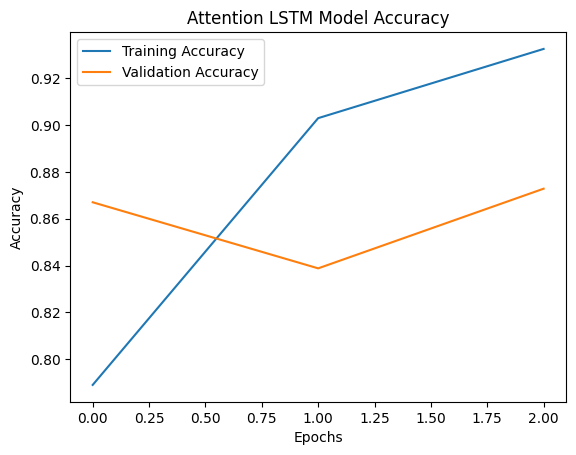

In [8]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Attention LSTM Model Accuracy")
plt.legend()
plt.show()

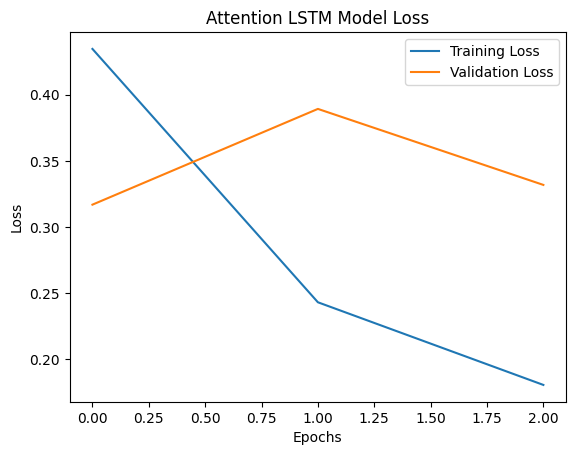

In [9]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Attention LSTM Model Loss")
plt.legend()
plt.show()